In [2]:
import astropy.units as u
import numpy as np
from snewpy.models import ccsn
from snewpy.flavor_transformation import EarthMatter, AdiabaticMSW
from snewpy.neutrino import MixingParameters, MassHierarchy, Flavor
from astropy.coordinates import AltAz
from snewpy.rate_calculator import RateCalculator, Detector, DetectionChannel, SmearingMatrix
import matplotlib.pyplot as plt
# Или подавляем все предупреждения 
import warnings
warnings.filterwarnings('ignore')
    
#get the suernova model
model = ccsn.Bollig_2016(progenitor_mass=27<<u.Msun)
#define the sampling points
energy = np.linspace(1,100,800)<<u.MeV
time = np.linspace(0,4,500)<<u.s
rc = RateCalculator()

/mnt/d/jinr/SNEWPY/snewpy_venv/lib/python3.10/site-packages/numpy/_core/getlimits.py:551: UserWarning: Signature b'\x00\xd0\xcc\xcc\xcc\xcc\xcc\xcc\xfb\xbf\x00\x00\x00\x00\x00\x00' for <class 'numpy.longdouble'> does not match any known type: falling back to type probe function.
This warnings indicates broken support for the dtype!
  machar = _get_machar(dtype)


In [3]:
#создание сврего детектора
xsec_ibd=rc.load_xsec('ibd',Flavor.NU_E_BAR)#сечение для ibd электронное антинейтрино из SNOwGLoBES
e_true  = np.arange(0,50,0.3)<<u.MeV #энергия нейтрино в пучку
e_smear = np.arange(0,50,0.3)<<u.MeV #измеренная энергия, которую увидит детектор(энергия позитрона) бины для интегрирования по энергии

#определим видимую энергию для IBD как функцию 
def E_vis_ibd(E_nu:u.Quantity):
    return E_nu - 784*u.keV

#SmearingMatrix.from_Gaussian — это конструктор на основе простого гауссовского распределения. 
#матрица вероятности того, что событие с энергией E_true будет зарегистрировано как E_smear.
m_smear_ibd=SmearingMatrix.from_Gaussian(e_true,e_smear,
                                         mean=E_vis_ibd, #среднее значение, пик Гаусса
                                         sigma=lambda e: 0.05*e #стандартное отклонение, ширина Гаусса, 5% разрешение
                                        )
#создайте детектор с теми же каналами IBD, но с тремя разными видами напыления
det = Detector('scint_det', mass=20<<u.kt,
               channels={
                   'ibd':DetectionChannel(flavor=Flavor.NU_E_BAR,
                                          xsec=xsec_ibd, 
                                          efficiency=1., 
                                          smearing = m_smear_ibd, 
                                          weight=0.1429) #массовая доля свободных протонов в сцинтилляторе
                                         })

In [8]:
def calc_rates(angles= [-90,90] <<u.deg,
               distance=1*u.kpc,
               mixing_params=MixingParameters(MassHierarchy.NORMAL)
              ):
    results = []
    for alt in angles:
        altaz = AltAz(alt=alt, az=0*u.deg) 
        flavor_transform = EarthMatter(AltAz=altaz, mixing_params=mixing_params) # Создание преобразования ароматов с учетом Земли
        flux = model.get_flux(time, energy, distance=distance, flavor_xform=flavor_transform)#поток нейтрино после осциляций
        ibd_rate = det.run(flux)['ibd'] #скорость событий в детекторе(число событий в секунду) автоматическое интегрирование по энергии в det
        time_bins = np.linspace(0,1,500)<<u.s
        r = ibd_rate.integrate('time', time_bins) #число событий во временном бине
        #print(flux, ibd_rate, r)
        results += [r]
    return results

In [9]:
rates = calc_rates()



*********************************************************

rho	/mnt/d/jinr/SNEWPY/BEMEWS/src/BEMEWS/data/PREM.rho.dat
Ye	/mnt/d/jinr/SNEWPY/BEMEWS/src/BEMEWS/data/PREM.Ye.dat
Loading a file Thrown in the function Read by the object /mnt/d/jinr/SNEWPY/BEMEWS/src/BEMEWS/data/PREM.rho.dat
Loading a file Thrown in the function Read by the object /mnt/d/jinr/SNEWPY/BEMEWS/src/BEMEWS/data/PREM.Ye.dat

m1	0	dm21^2	7.49e-05	dm32	0.0024381
theta12V	33.68	theta13V	8.56	theta23V	43.3	deltaCP	212

NE	800	Emin	1	Emax	100

output filename stem	:-90,0:7.49e-05,0.0024381,33.68,8.56,43.3,212:800,1,100

Number of domains	13
Domain	1:	0	to	1.2e+06
Domain	2:	1.2e+06	to	2.14e+06
Domain	3:	2.14e+06	to	3.97e+07
Domain	4:	3.97e+07	to	6.67e+07
Domain	5:	6.67e+07	to	2.888e+08
Domain	6:	2.888e+08	to	5.1465e+08
Domain	7:	5.1465e+08	to	7.5895e+08
Domain	8:	7.5895e+08	to	9.848e+08
Domain	9:	9.848e+08	to	1.2069e+09
Domain	10:	1.2069e+09	to	1.2339e+09
Domain	11:	1.2339e+09	to	1.27146e+09
Domain	12:	1.27146e+09	to	1

[<Quantity 45.6299498>, <Quantity 11.40748745>, <Quantity 5.06999442>, <Quantity 2.85187186>, <Quantity 1.82519799>, <Quantity 1.26749861>, <Quantity 0.93122347>, <Quantity 0.71296797>, <Quantity 0.56333271>, <Quantity 0.4562995>]


Text(0.5, 0, 'Distance, kpc')

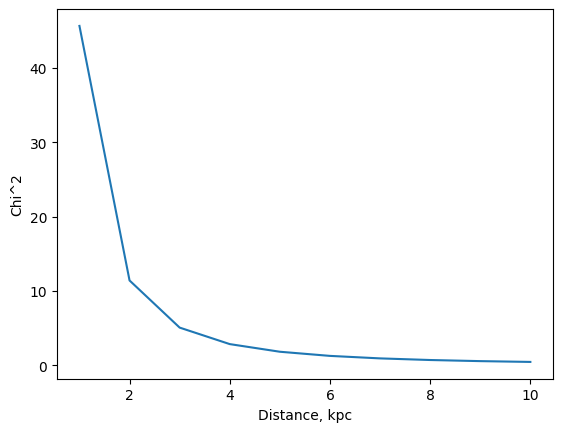

In [36]:
chi=[]
distance = range(1, 11)
for dis in distance:
    rH1, rH0 = rates[0].array.squeeze()/(dis**2), rates[1].array.squeeze()/(dis**2)
    chi2 = np.sum(((rH1 - rH0)**2)/rH0)
    chi += [chi2]
print(chi)
plt.plot(distance, chi)
plt.ylabel('Chi^2')
plt.xlabel('Distance, kpc')

In [4]:
def calc_rates2(angles,
               distance=1*u.kpc,
               mixing_params=MixingParameters(MassHierarchy.NORMAL)
              ):
    results = []
    for alt in angles:
        altaz = AltAz(alt=alt, az=0*u.deg) 
        flavor_transform = EarthMatter(AltAz=altaz, mixing_params=mixing_params) # Создание преобразования ароматов с учетом Земли
        flux = model.get_flux(time, energy, distance=distance, flavor_xform=flavor_transform)#поток нейтрино после осциляций
        ibd_rate = det.run(flux)['ibd'] #скорость событий в детекторе(число событий в секунду) автоматическое интегрирование по энергии в det
        time_bins = np.linspace(0,1,100)<<u.s
        r = ibd_rate.integrate('time', time_bins) #число событий во временном бине
        #print(flux, ibd_rate, r)
        results += [r]
    return results

In [5]:
angles = range(-90, 3, 3)
rates = calc_rates2(angles <<u.deg)



*********************************************************

rho	/mnt/d/jinr/SNEWPY/BEMEWS/src/BEMEWS/data/PREM.rho.dat
Ye	/mnt/d/jinr/SNEWPY/BEMEWS/src/BEMEWS/data/PREM.Ye.dat
Loading a file Thrown in the function Read by the object /mnt/d/jinr/SNEWPY/BEMEWS/src/BEMEWS/data/PREM.rho.dat
Loading a file Thrown in the function Read by the object /mnt/d/jinr/SNEWPY/BEMEWS/src/BEMEWS/data/PREM.Ye.dat

m1	0	dm21^2	7.49e-05	dm32	0.0024381
theta12V	33.68	theta13V	8.56	theta23V	43.3	deltaCP	212

NE	800	Emin	1	Emax	100

output filename stem	:-90,0:7.49e-05,0.0024381,33.68,8.56,43.3,212:800,1,100

Number of domains	13
Domain	1:	0	to	1.2e+06
Domain	2:	1.2e+06	to	2.14e+06
Domain	3:	2.14e+06	to	3.97e+07
Domain	4:	3.97e+07	to	6.67e+07
Domain	5:	6.67e+07	to	2.888e+08
Domain	6:	2.888e+08	to	5.1465e+08
Domain	7:	5.1465e+08	to	7.5895e+08
Domain	8:	7.5895e+08	to	9.848e+08
Domain	9:	9.848e+08	to	1.2069e+09
Domain	10:	1.2069e+09	to	1.2339e+09
Domain	11:	1.2339e+09	to	1.27146e+09
Domain	12:	1.27146e+09	to	1

[<Quantity 47.400475>, <Quantity 47.58536972>, <Quantity 48.02920498>, <Quantity 47.86502209>, <Quantity 46.34529844>, <Quantity 42.72624371>, <Quantity 41.28491604>, <Quantity 43.63435582>, <Quantity 44.73489413>, <Quantity 46.32500428>, <Quantity 48.38247026>, <Quantity 47.59186238>, <Quantity 46.41860475>, <Quantity 46.31064404>, <Quantity 48.62366433>, <Quantity 49.72383038>, <Quantity 48.7297662>, <Quantity 51.44206474>, <Quantity 51.76948267>, <Quantity 49.05083469>, <Quantity 54.09091818>, <Quantity 53.37115746>, <Quantity 55.6850616>, <Quantity 55.59710086>, <Quantity 52.4552818>, <Quantity 62.35949883>, <Quantity 50.52506924>, <Quantity 68.95309105>, <Quantity 36.50314383>, <Quantity 66.06342973>, <Quantity 0.>]


Text(0.5, 0, 'Angles, deg')

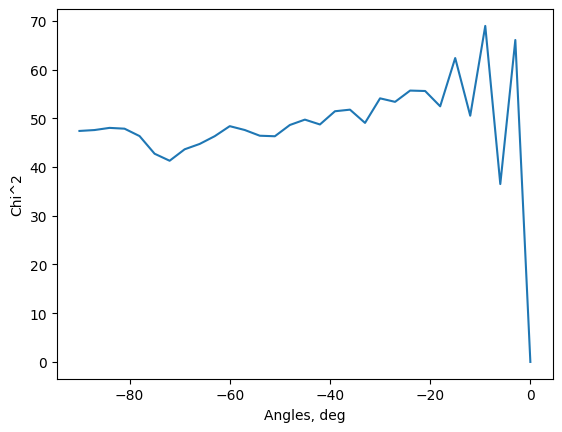

In [15]:
from scipy.stats import chi2, norm
chi, p, Z = [], [], []
rH0=rates[-1].array.squeeze()
dof = 16666
for rate in rates:
    chi_2 = np.sum(((rate.array.squeeze() - rH0)**2)/rH0)
    chi += [chi_2]
    '''
    p_value = 1 - chi2.cdf(chi_2, dof)
    z = norm.ppf(1 - p_value)
    p += [p_value]
    Z += [z]
    '''
print(chi)
plt.plot(angles, chi)
plt.ylabel('Chi^2')
plt.xlabel('Angles, deg')

## Данные в сравнении с моделированием на всех углах

In [1]:
import matplotlib.pyplot as plt
from snewpy.flux import Container
import numpy as np
from tqdm.auto import tqdm, trange
def load_data(angle, distance=1):
    data = Container.load(f'ibd_Juno_rate.{angle:d}.npz').array.squeeze().to_value('')
    data *= (1./distance)**2
    return data


/mnt/d/jinr/SNEWPY/snewpy_venv/lib/python3.10/site-packages/numpy/_core/getlimits.py:551: UserWarning: Signature b'\x00\xd0\xcc\xcc\xcc\xcc\xcc\xcc\xfb\xbf\x00\x00\x00\x00\x00\x00' for <class 'numpy.longdouble'> does not match any known type: falling back to type probe function.
This warnings indicates broken support for the dtype!
  machar = _get_machar(dtype)


In [2]:
def calc_chi2(samples, expected):
    N_samples = len(samples)
    dN = ((samples-expected)**2/expected)
    chi2 = dN.reshape(N_samples,-1).sum(axis=-1)
    return chi2/expected.size

In [3]:
distance=0.1
data = load_data(-65, distance)
samples = np.random.poisson(lam = data, size=(500, *data.shape))
chi2_dict = {}
for ang in trange(-90, 2, 5):
    exp = load_data(ang, distance)
    chi2_dict[ang] = calc_chi2(samples, exp)

  0%|          | 0/19 [00:00<?, ?it/s]

In [4]:
chi2 = np.stack(list(chi2_dict.values()))
angles = np.array(list(chi2_dict.keys()))
chi2_med, *chi2_1s = np.quantile(chi2, q=(0.5, 0.5-0.68/2, 0.5+0.68/2), axis=1)

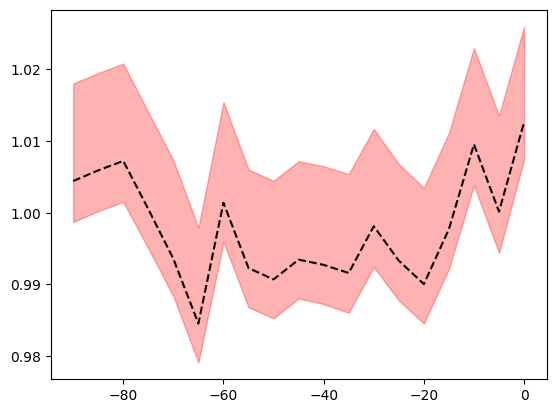

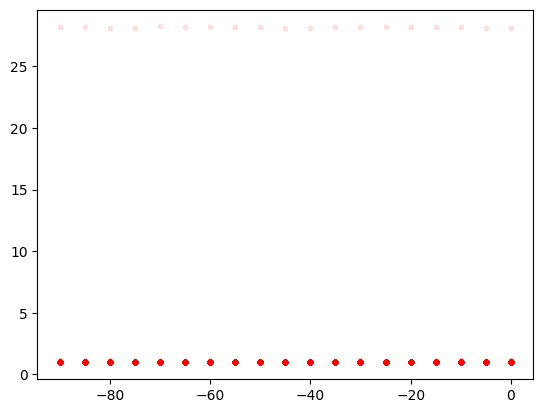

In [5]:
plt.fill_between(angles, *chi2_1s, alpha=0.3, color='r')
plt.plot(angles, chi2_med,'--k')
plt.show()
plt.plot(angles, chi2, 'r.',alpha=0.1);

In [8]:
for samples in samples0,samples1,samples2:
    chi2 = calc_chi2(samples, exp0)
    plt.hist(chi2, bins=100, alpha=0.5)
plt.show()

NameError: name 'samples0' is not defined

In [6]:
rH1, rH0 = exp1, exp0
ratio = (rH1-rH0)/np.sqrt(rH0)
plt.pcolormesh(ratio.T**2)
plt.colorbar()

NameError: name 'exp1' is not defined

In [7]:
calc_chi2(samples0, exp0)

NameError: name 'samples0' is not defined

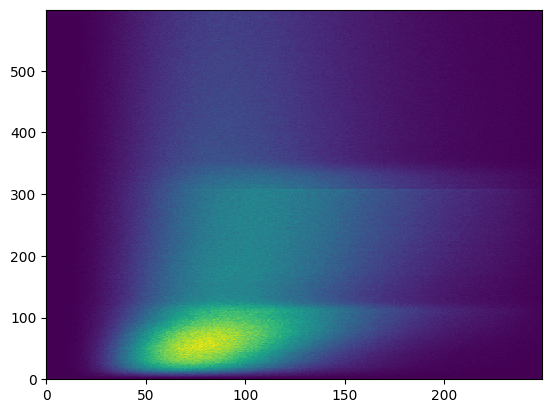

In [9]:
plt.pcolormesh(samples[1])